<a href="https://colab.research.google.com/github/karquiza/task-delay-risk-predictor/blob/ML_Model/ML_Model_for_PM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train: 780 rows (60.0%)
Val:   260 rows (20.0%)
Test:  260 rows (20.0%)
=== Logistic Regression ===
ROC-AUC (Weighted OvR): 0.8150
              precision    recall  f1-score   support

         Low       0.76      0.81      0.78       129
      Medium       0.73      0.61      0.67       118
        High       0.42      0.85      0.56        13

    accuracy                           0.72       260
   macro avg       0.64      0.75      0.67       260
weighted avg       0.73      0.72      0.72       260


--- Logistic Regression Confusion Matrix (Counts) ---
                Pred: Low  Pred: Medium  Pred: High
Actual: Low           104            24           1
Actual: Medium         32            72          14
Actual: High            0             2          11

--- Logistic Regression Confusion Matrix (Row % / Recall) ---
                Pred: Low (%)  Pr

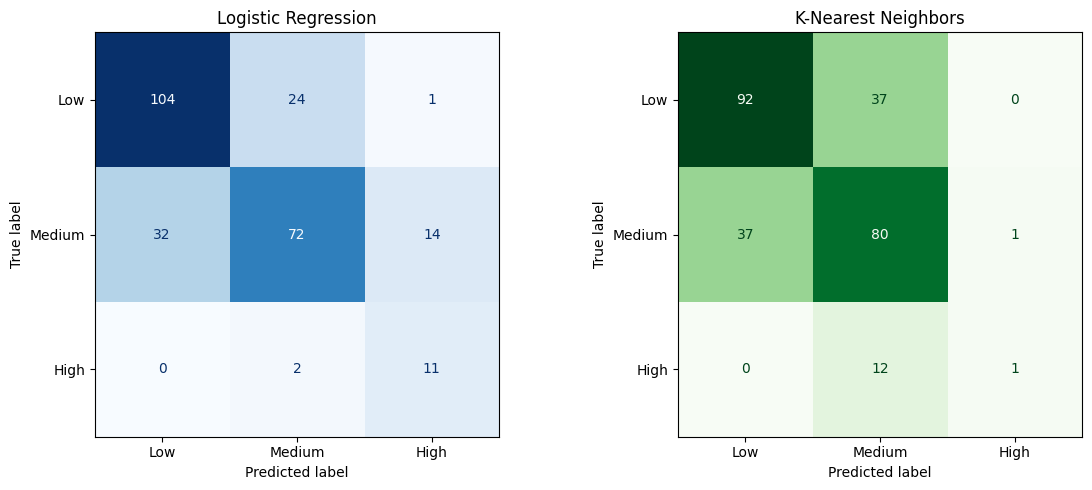

=== Logistic Regression ===
ROC-AUC (Weighted OvR): 0.8150
              precision    recall  f1-score   support

         Low       0.76      0.81      0.78       129
      Medium       0.73      0.61      0.67       118
        High       0.42      0.85      0.56        13

    accuracy                           0.72       260
   macro avg       0.64      0.75      0.67       260
weighted avg       0.73      0.72      0.72       260


--- Logistic Regression Confusion Matrix (Counts) ---
                Pred: Low  Pred: Medium  Pred: High
Actual: Low           104            24           1
Actual: Medium         32            72          14
Actual: High            0             2          11

--- Logistic Regression Confusion Matrix (Row % / Recall) ---
                Pred: Low (%)  Pred: Medium (%)  Pred: High (%)
Actual: Low              80.6              18.6             0.8
Actual: Medium           27.1              61.0            11.9
Actual: High              0.0             

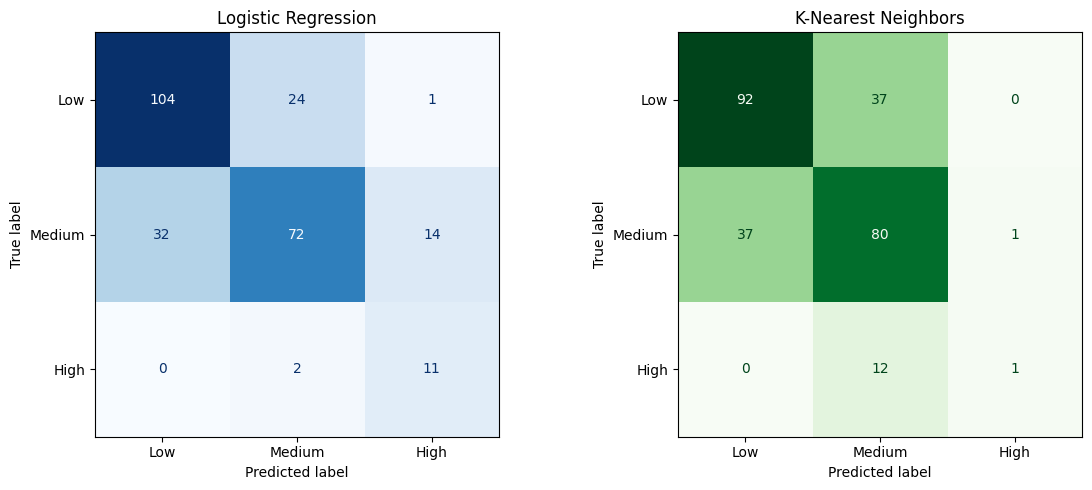

In [13]:
import os
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = "/content/drive/MyDrive/Seneca/MAI 104/Group Project Documents"
else:
    DATA = "."  # Fallback for running locally

# 1. Load data using the full path
file_path = os.path.join(DATA, "Synthetic Data V2.csv")
df = pd.read_csv(file_path)

# 2. Map Risk_Outcome to Low, Medium, High
risk_map = {"On_Time": "Low", "Delayed": "Medium", "Missed": "High"}
df["Risk_Level"] = df["Risk_Outcome"].map(risk_map)

# 3. Define features and target (drop leakage & ID columns)
num_cols = [
    "Story_Points", "Assignee_Active_Workload_SP", "Assignee_Experience_Years",
    "Upstream_Delay_Days", "Scope_Creep_Changes", "Logged_Blockers"
]
bin_cols = ["Is_Milestone_Gate", "External_Dependency"]
cat_cols = ["Phase", "Task_Category", "Current_Board_Status"]

X = df[num_cols + bin_cols + cat_cols]
y = df["Risk_Level"]
groups = df["Simulation_Run_ID"]

# 4. Split by Simulation_Run_ID (60% Train, 20% Val, 20% Test)

# First split: 80% Train+Val, 20% Test
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.20)
train_val_idx, test_idx = next(gss_test.split(X, y, groups))

X_train_val, y_train_val, groups_train_val = (
    X.iloc[train_val_idx],
    y.iloc[train_val_idx],
    groups.iloc[train_val_idx],
)
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

# Second split: 75% of 80% = 60% Train, 25% of 80% = 20% Val
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25)
train_idx, val_idx = next(gss_val.split(X_train_val, y_train_val, groups_train_val))

X_train, y_train = X_train_val.iloc[train_idx], y_train_val.iloc[train_idx]
X_val, y_val = X_train_val.iloc[val_idx], y_train_val.iloc[val_idx]

# Optional: Verify proportions and zero group overlap
print(f"Train: {len(X_train)} rows ({len(X_train)/len(X):.1%})")
print(f"Val:   {len(X_val)} rows ({len(X_val)/len(X):.1%})")
print(f"Test:  {len(X_test)} rows ({len(X_test)/len(X):.1%})")


# 5. Preprocessing pipeline
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("bin", "passthrough", bin_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

labels = ["Low", "Medium", "High"]

def show_detailed_cm(y_true, y_pred, model_name):
    # Raw counts
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual: {l}" for l in labels],
        columns=[f"Pred: {l}" for l in labels]
    )
    print(f"\n--- {model_name} Confusion Matrix (Counts) ---")
    print(cm_df)

    # Row-normalized (shows recall % per actual class)
    cm_norm = confusion_matrix(y_true, y_pred, labels=labels, normalize="true")
    cm_norm_df = pd.DataFrame(
        (cm_norm * 100).round(1),
        index=[f"Actual: {l}" for l in labels],
        columns=[f"Pred: {l} (%)" for l in labels]
    )
    print(f"\n--- {model_name} Confusion Matrix (Row % / Recall) ---")
    print(cm_norm_df)
    return cm

# 6. Logistic Regression Model
lr_model = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
])
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)
lr_probs = lr_model.predict_proba(X_test)
lr_auc = roc_auc_score(y_test, lr_probs, multi_class="ovr", average="weighted")

print("=== Logistic Regression ===")
print(f"ROC-AUC (Weighted OvR): {lr_auc:.4f}")
print(classification_report(y_test, lr_preds, labels=labels))
lr_cm = show_detailed_cm(y_test, lr_preds, "Logistic Regression")

# 7. KNN Model
knn_model = Pipeline([
    ("prep", preprocessor),
    ("clf", KNeighborsClassifier(n_neighbors=5, weights="distance"))
])
knn_model.fit(X_train, y_train)
knn_preds = knn_model.predict(X_test)
knn_probs = knn_model.predict_proba(X_test)
knn_auc = roc_auc_score(y_test, knn_probs, multi_class="ovr", average="weighted")

print("\n=== K-Nearest Neighbors ===")
print(f"ROC-AUC (Weighted OvR): {knn_auc:.4f}")
print(classification_report(y_test, knn_preds, labels=labels))
knn_cm = show_detailed_cm(y_test, knn_preds, "K-Nearest Neighbors")

# 8. Plot Side-by-Side Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(lr_cm, display_labels=labels).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay(knn_cm, display_labels=labels).plot(ax=axes[1], cmap="Greens", colorbar=False)
axes[1].set_title("K-Nearest Neighbors")

plt.tight_layout()
plt.show()
labels = ["Low", "Medium", "High"]

def show_detailed_cm(y_true, y_pred, model_name):
    # Raw counts
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual: {l}" for l in labels],
        columns=[f"Pred: {l}" for l in labels]
    )
    print(f"\n--- {model_name} Confusion Matrix (Counts) ---")
    print(cm_df)

    # Row-normalized (shows recall % per actual class)
    cm_norm = confusion_matrix(y_true, y_pred, labels=labels, normalize="true")
    cm_norm_df = pd.DataFrame(
        (cm_norm * 100).round(1),
        index=[f"Actual: {l}" for l in labels],
        columns=[f"Pred: {l} (%)" for l in labels]
    )
    print(f"\n--- {model_name} Confusion Matrix (Row % / Recall) ---")
    print(cm_norm_df)
    return cm

# 6. Logistic Regression Model
lr_model = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
])
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)
lr_probs = lr_model.predict_proba(X_test)
lr_auc = roc_auc_score(y_test, lr_probs, multi_class="ovr", average="weighted")

print("=== Logistic Regression ===")
print(f"ROC-AUC (Weighted OvR): {lr_auc:.4f}")
print(classification_report(y_test, lr_preds, labels=labels))
lr_cm = show_detailed_cm(y_test, lr_preds, "Logistic Regression")

# 7. KNN Model
knn_model = Pipeline([
    ("prep", preprocessor),
    ("clf", KNeighborsClassifier(n_neighbors=5, weights="distance"))
])
knn_model.fit(X_train, y_train)
knn_preds = knn_model.predict(X_test)
knn_probs = knn_model.predict_proba(X_test)
knn_auc = roc_auc_score(y_test, knn_probs, multi_class="ovr", average="weighted")

print("\n=== K-Nearest Neighbors ===")
print(f"ROC-AUC (Weighted OvR): {knn_auc:.4f}")
print(classification_report(y_test, knn_preds, labels=labels))
knn_cm = show_detailed_cm(y_test, knn_preds, "K-Nearest Neighbors")

# 8. Plot Side-by-Side Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(lr_cm, display_labels=labels).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay(knn_cm, display_labels=labels).plot(ax=axes[1], cmap="Greens", colorbar=False)
axes[1].set_title("K-Nearest Neighbors")

plt.tight_layout()
plt.show()